In [50]:
from pathlib import Path
import sys

def find_project_root():
    here = Path.cwd()
    for p in [here, *here.parents]:
        if (p / "utils").exists() and (p / "models").exists():
            return p
    for p in [here, *here.parents]:
        if any((p / m).exists() for m in (".git", "requirements.txt", "pyproject.toml")):
            return p
    return here

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

from utils.data_loadingV3_random import load_data, load_test_data
from models.rnn import RNNModel
from utils.simple_lds_loss import SimpleLDSLoss
from utils.fds import FDS

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Using device: cuda
⚠️  RADICAL SIMPLIFICATION: Vanilla RNN + minimal dropout + V3 dataloader


In [ ]:
CONFIG = {
    'MODEL_TYPE': 'RNN',
    'HIDDEN_SIZE': 128,   # Simpler config for vanilla RNN
    'NUM_LAYERS': 2,      # Keep it simple
    'DROPOUT': 0.1,       # MINIMAL dropout - let it learn (V11_RNN baseline)
    # 'DROPOUT': 0.05,    # V11B: Even less dropout - more learning
    # 'DROPOUT': 0.15,    # V11C: Slightly more dropout - balance
    
    'LDS_ENABLED': True,
    'BASE_LOSS': 'smoothl1',
    'SMOOTHL1_BETA': 0.1,
    'REWEIGHT': 'sqrt_inv',  # Back to balanced approach
    'NUM_BINS': 100,  # Standard bins
    'LDS_KERNEL': 'gaussian',
    'LDS_KS': 5,      # Standard smoothing
    'LDS_SIGMA': 2,   # Standard smoothing
    'FDS_ENABLED': False,
    'FDS_START_EPOCH': 10,
    'FDS_SMOOTH_EPOCH': 15,
    'FDS_FEATURE_DIM': 64,
    'FDS_KERNEL': 'gaussian',
    'FDS_KS': 5,
    'FDS_SIGMA': 2,
    'NUM_EPOCHS': 100,     # V11D: Extended training (was 70)
    'PATIENCE': 30,
    'LEARNING_RATE': 2e-4,     # Standard learning rate
    'WEIGHT_DECAY': 1e-5,      # Minimal regularization
    
    'TRAIN_PATH': r'../datasets_challenge/train',
    'TEST_PATH': r'../datasets_challenge/test',
    'VAL_RATIO': 0.2,
    'BATCH_SIZE': 64,
    'COLUMNS_TO_DROP': ['sideSlip', 'vyCG', 'longitude', 'latitude', 'time'],
    'SEQUENCE_LENGTH': 20,
    'THRESHOLD': True,
    'THRESHOLD_VALUE': 3.0,
    'THRESHOLD_COLUMN': 'vxCG',
    'TARGET': 'sideSlip',
    'SCALING': True,
    'SEED': 42,
    
    'BAND_THRESHOLDS': {
        'many': (0.0, 4.5),
        'medium': (4.5, 8.0),
        'few': (8.0, 100.0),
    },
    'DIST_CSV': r'../datasets_challenge/sideSlip_distribution.csv',
    
    'USE_BEST_VAL': True,
    'MODEL_PATH': 'best_model_v11_rnn.pth',    # Change for variants: v11b, v11c, v11d
    'MODEL_PATH': 'best_model_v11d.pth',
    'VERSION': 'V11D',
    'SUBMISSION_CSV': 'predictions_v11d.csv',
}


In [53]:
train_loader, val_loader, scaler, train_dataset, val_dataset = load_data(
    train_path=CONFIG['TRAIN_PATH'],
    val_ratio=CONFIG['VAL_RATIO'],
    batchsize=CONFIG['BATCH_SIZE'],
    columns_to_drop=CONFIG['COLUMNS_TO_DROP'],
    sequence_length=CONFIG['SEQUENCE_LENGTH'],
    threshold=CONFIG['THRESHOLD'],
    threshold_value=CONFIG['THRESHOLD_VALUE'],
    threshold_column=CONFIG['THRESHOLD_COLUMN'],
    target=CONFIG['TARGET'],
    scaling=CONFIG['SCALING'],
    seed=CONFIG['SEED']
)

train_targets = []
for _, y in train_loader:
    train_targets.append(y)
train_targets = torch.cat(train_targets).numpy()

V3 Data Loader: RANDOM Stratified Split (Better Generalization)

Processing 22 files...
Total groups: 42

🔧 Applying domain-specific clipping to reduce distribution shift...
Total groups: 42

🔧 Applying domain-specific clipping to reduce distribution shift...
✅ Applied RobustScaler(5-95 percentile) + MinMaxScaler(-1, 1)

✅ RANDOM Split (should match test distribution better):
Train: Many=92.0%, Medium=6.4%, Few=1.6%
Val:   Many=82.0%, Medium=12.2%, Few=5.7%

Train: 124,692 sequences | Val: 12,388 sequences

✅ Applied RobustScaler(5-95 percentile) + MinMaxScaler(-1, 1)

✅ RANDOM Split (should match test distribution better):
Train: Many=92.0%, Medium=6.4%, Few=1.6%
Val:   Many=82.0%, Medium=12.2%, Few=5.7%

Train: 124,692 sequences | Val: 12,388 sequences



In [54]:
input_size = next(iter(train_loader))[0].shape[-1]

if CONFIG['MODEL_TYPE'] == 'RNN':
    model = RNNModel(
        input_size=input_size,
        hidden_size=CONFIG['HIDDEN_SIZE'],
        num_layers=CONFIG['NUM_LAYERS'],
        dropout=CONFIG['DROPOUT'],
        use_batch_norm=False,  # Keep it simple
        output_size=1
    )
else:
    raise ValueError(f"Unknown model type: {CONFIG['MODEL_TYPE']}")

model = model.to(device)
print(f"Model parameters: {model.get_num_params():,}")

Model parameters: 60,801


In [55]:
criterion = SimpleLDSLoss(
    train_targets=train_targets,
    base=CONFIG['BASE_LOSS'],
    smoothl1_beta=CONFIG['SMOOTHL1_BETA'],
    reweight=CONFIG['REWEIGHT'],
    lds=CONFIG['LDS_ENABLED'],
    lds_kernel=CONFIG['LDS_KERNEL'],
    lds_ks=CONFIG['LDS_KS'],
    lds_sigma=CONFIG['LDS_SIGMA'],
    num_bins=CONFIG['NUM_BINS']
).to(device)

if CONFIG['FDS_ENABLED']:
    fds = FDS(
        feat_dim=CONFIG['FDS_FEATURE_DIM'],
        num_bins=CONFIG['NUM_BINS'],
        kernel=CONFIG['FDS_KERNEL'],
        ks=CONFIG['FDS_KS'],
        sigma=CONFIG['FDS_SIGMA'],
        momentum=CONFIG['FDS_MOMENTUM'],
        start_update=CONFIG['FDS_START_EPOCH'],
        start_smooth=CONFIG['FDS_SMOOTH_EPOCH']
    ).to(device)
else:
    fds = None

✅ LDS enabled: gaussian kernel (ks=5, sigma=2)

SimpleLDSLoss Configuration
Base loss: smoothl1 (beta=0.1)
Reweight: sqrt_inv
Bins: 100
Weight range: [0.020, 5.589]
Weight mean: 1.000 (normalized to 1.0)



In [56]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=CONFIG['LEARNING_RATE'],
    weight_decay=CONFIG['WEIGHT_DECAY']
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer,
    T_0=CONFIG['NUM_EPOCHS'],
    T_mult=1,
    eta_min=1e-6
)

In [57]:
def compute_band_metrics(y_true, y_pred, dist_csv_path):
    dist_df = pd.read_csv(dist_csv_path)
    band_dict = dict(zip(dist_df['sideSlip'].values, dist_df['band'].values))
    
    y_true_np = y_true.cpu().numpy().flatten()
    y_pred_np = y_pred.cpu().numpy().flatten()
    
    bands = []
    for val in y_true_np:
        val_rounded = round(float(val), 1)
        bands.append(band_dict.get(val_rounded, 'unknown'))
    
    df = pd.DataFrame({
        'true': y_true_np,
        'pred': y_pred_np,
        'band': bands,
        'error': np.abs(y_true_np - y_pred_np)
    })
    
    band_metrics = df.groupby('band')['error'].agg(['mean', 'count']).to_dict('index')
    
    return {
        'many': band_metrics.get('many', {'mean': 0.0, 'count': 0})['mean'],
        'medium': band_metrics.get('medium', {'mean': 0.0, 'count': 0})['mean'],
        'few': band_metrics.get('few', {'mean': 0.0, 'count': 0})['mean'],
        'counts': {
            'many': band_metrics.get('many', {'mean': 0.0, 'count': 0})['count'],
            'medium': band_metrics.get('medium', {'mean': 0.0, 'count': 0})['count'],
            'few': band_metrics.get('few', {'mean': 0.0, 'count': 0})['count']
        }
    }

def train_one_epoch(model, loader, criterion, optimizer, device, fds=None, epoch=0):
    model.train()
    total_loss = 0
    
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        
        if fds is not None and CONFIG['FDS_ENABLED']:
            features, pred = model(X, return_features=True)
            features = fds(features, y, criterion.bin_edges, epoch, train=True)
        else:
            pred = model(X)
        
        loss = criterion(pred, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item()
    
    return total_loss / len(loader)

@torch.no_grad()
def validate(model, loader, criterion, device, dist_csv_path, fds=None, epoch=0):
    model.eval()
    total_loss = 0
    all_preds = []
    all_targets = []
    
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        
        if fds is not None and CONFIG['FDS_ENABLED']:
            features, pred = model(X, return_features=True)
            features = fds(features, y, criterion.bin_edges, epoch, train=False)
        else:
            pred = model(X)
        
        loss = criterion(pred, y)
        total_loss += loss.item()
        all_preds.append(pred)
        all_targets.append(y)
    
    all_preds = torch.cat(all_preds)
    all_targets = torch.cat(all_targets)
    band_metrics = compute_band_metrics(all_targets, all_preds, dist_csv_path)
    
    return total_loss / len(loader), band_metrics

In [58]:
best_few_mae = float('inf')
best_many_mae = float('inf')
patience_counter = 0
history = {
    'train_loss': [],
    'val_loss': [],
    'many_mae': [],
    'medium_mae': [],
    'few_mae': []
}

for epoch in range(CONFIG['NUM_EPOCHS']):
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device, fds=fds, epoch=epoch)
    val_loss, band_metrics = validate(model, val_loader, criterion, device, CONFIG['DIST_CSV'], fds=fds, epoch=epoch)
    
    if fds is not None and CONFIG['FDS_ENABLED']:
        fds.update_last_epoch_stats(epoch)
    
    scheduler.step()
    
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['many_mae'].append(band_metrics['many'])
    history['medium_mae'].append(band_metrics['medium'])
    history['few_mae'].append(band_metrics['few'])
    
    print(f"Epoch {epoch+1}/{CONFIG['NUM_EPOCHS']} | Train: {train_loss:.6f} | Val: {val_loss:.6f} | "
          f"Many: {band_metrics['many']:.4f} | Medium: {band_metrics['medium']:.4f} | Few: {band_metrics['few']:.4f}")
    
    if band_metrics['many'] < best_many_mae:
        best_many_mae = band_metrics['many']
        best_few_mae = band_metrics['few']
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_few_mae': band_metrics['few'],
            'best_many_mae': band_metrics['many'],
            'band_metrics': band_metrics,
            'config': CONFIG
        }, CONFIG['MODEL_PATH'])
        print(f"  New best: Many {best_many_mae:.4f} | Few {best_few_mae:.4f}")

print(f"\nTraining complete. Best Val Many: {best_many_mae:.4f} | Few: {best_few_mae:.4f}")

Epoch 1/100 | Train: 0.024131 | Val: 0.035767 | Many: 0.3551 | Medium: 0.7727 | Few: 1.0644
  New best: Many 0.3551 | Few 1.0644
Epoch 2/100 | Train: 0.016221 | Val: 0.035627 | Many: 0.2734 | Medium: 0.8377 | Few: 1.1356
  New best: Many 0.2734 | Few 1.1356
Epoch 2/100 | Train: 0.016221 | Val: 0.035627 | Many: 0.2734 | Medium: 0.8377 | Few: 1.1356
  New best: Many 0.2734 | Few 1.1356
Epoch 3/100 | Train: 0.014438 | Val: 0.031165 | Many: 0.2502 | Medium: 0.6464 | Few: 1.0216
  New best: Many 0.2502 | Few 1.0216
Epoch 3/100 | Train: 0.014438 | Val: 0.031165 | Many: 0.2502 | Medium: 0.6464 | Few: 1.0216
  New best: Many 0.2502 | Few 1.0216
Epoch 4/100 | Train: 0.013352 | Val: 0.029433 | Many: 0.2525 | Medium: 0.6541 | Few: 0.9262
Epoch 4/100 | Train: 0.013352 | Val: 0.029433 | Many: 0.2525 | Medium: 0.6541 | Few: 0.9262
Epoch 5/100 | Train: 0.012628 | Val: 0.026902 | Many: 0.2308 | Medium: 0.5713 | Few: 0.8778
  New best: Many 0.2308 | Few 0.8778
Epoch 5/100 | Train: 0.012628 | Val: 0.026

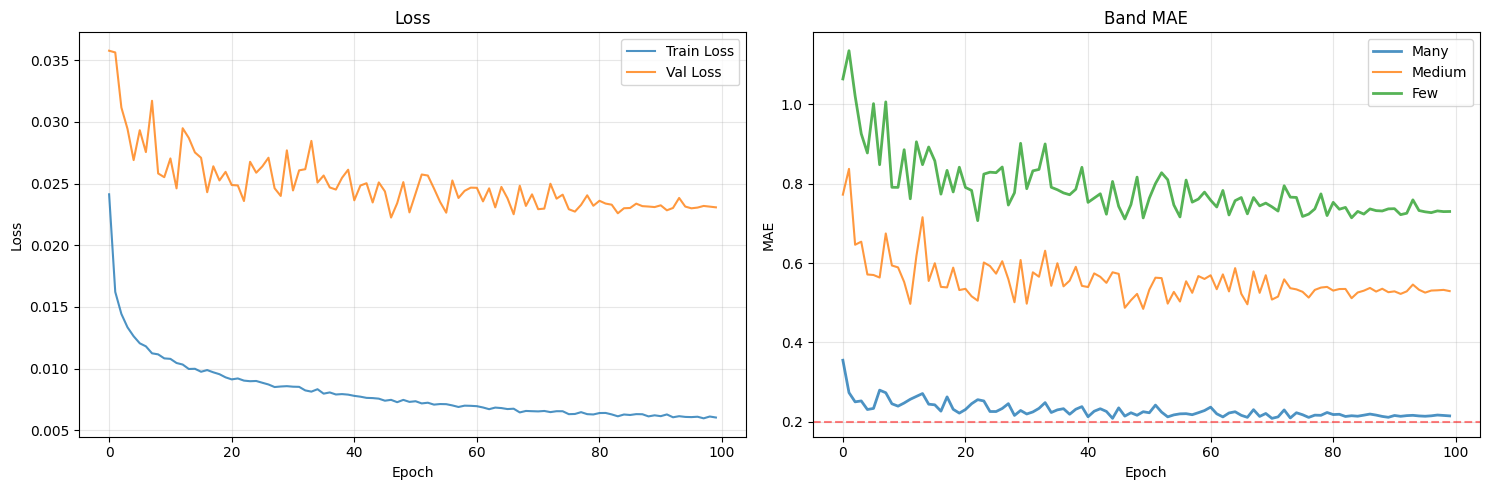

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(history['train_loss'], label='Train Loss', alpha=0.8)
axes[0].plot(history['val_loss'], label='Val Loss', alpha=0.8)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history['many_mae'], label='Many', alpha=0.8, linewidth=2)
axes[1].plot(history['medium_mae'], label='Medium', alpha=0.8)
axes[1].plot(history['few_mae'], label='Few', alpha=0.8, linewidth=2)
axes[1].axhline(y=0.20, color='r', linestyle='--', alpha=0.5)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MAE')
axes[1].set_title('Band MAE')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'training_curves_{CONFIG["VERSION"]}.png', dpi=150, bbox_inches='tight')
plt.show()

In [61]:
checkpoint = torch.load(CONFIG['MODEL_PATH'])
model.load_state_dict(checkpoint['model_state_dict'])
best_epoch = checkpoint['epoch']
model.eval()

print(f"Best model epoch {checkpoint['epoch']+1}: Many {checkpoint['band_metrics']['many']:.4f} | "
      f"Medium {checkpoint['band_metrics']['medium']:.4f} | Few {checkpoint['band_metrics']['few']:.4f}")

Best model epoch 71: Many 0.2086 | Medium 0.5081 | Few 0.7420


In [62]:
test_loader = load_test_data(
    test_path=CONFIG['TEST_PATH'],
    scaler=scaler,
    columns_to_drop=CONFIG['COLUMNS_TO_DROP'],
    sequence_length=CONFIG['SEQUENCE_LENGTH'],
    threshold_value=CONFIG['THRESHOLD_VALUE'],
    threshold_column=CONFIG['THRESHOLD_COLUMN'],
    batchsize=CONFIG['BATCH_SIZE'],
    seed=CONFIG['SEED']
)

📂 Loading Test Data

Found 11 test files

🔧 Applying domain-specific clipping to test data...
✅ Test sequences: 49,328
   ✅ Matches Kaggle requirement!

✅ Test sequences: 49,328
   ✅ Matches Kaggle requirement!



In [63]:
model.eval()
test_preds = []

with torch.no_grad():
    for x in test_loader:
        x = x.to(device).float()
        
        if fds is not None and CONFIG['FDS_ENABLED']:
            features, pred = model(x, return_features=True)
            dummy_y = torch.zeros(x.size(0), device=device)
            features = fds(features, dummy_y, criterion.bin_edges, best_epoch, train=False)
        else:
            pred = model(x)
        
        test_preds.append(pred.cpu().numpy())

test_preds = np.concatenate(test_preds).flatten()
print(f"Test predictions: {len(test_preds)} samples, range [{test_preds.min():.3f}, {test_preds.max():.3f}]")

Test predictions: 49328 samples, range [-7.370, 9.605]


In [64]:
y_pred = pd.DataFrame({
    "id": range(len(test_preds)),
    "predicted_sideslip": test_preds
})

y_pred.to_csv(CONFIG['SUBMISSION_CSV'], index=False)
print(f"Saved {CONFIG['SUBMISSION_CSV']}: {len(test_preds)} predictions")

Saved predictions_v11d.csv: 49328 predictions
